<h1>Extracting and Visualizing Stock Data</h1>
<h2>Description</h2>

Extracting essential data from a dataset and displaying it is a necessary part of data science; therefore individuals can make correct decisions based on the data. In this assignment, you will extract some stock data, you will then display this data in a graph.


In [1]:
import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup

In [2]:
import warnings
# Ignore all warnings
warnings.filterwarnings('ignore', category=FutureWarning)

## Define Graphing Function

In [4]:
# The make_graph function has been modified to use Matplotlib for static graphs. Earlier, it used Plotly to generate interactive dashboards, which caused issues when uploading the notebook in the MARK assignment submission.

import matplotlib.pyplot as plt

def make_graph(stock_data, revenue_data, stock):
    stock_data_specific = stock_data[stock_data.Date <= '2021-06-14']
    revenue_data_specific = revenue_data[revenue_data.Date <= '2021-04-30']

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # Stock price
    axes[0].plot(pd.to_datetime(stock_data_specific.Date), stock_data_specific.Close.astype('float'), label='Share Price', color='blue')
    axes[0].set_ylabel('Price ($US)')
    axes[0].set_title(f'{stock} - Historical Share Price')

    # Revenue
    axes[1].plot(pd.to_datetime(revenue_data_specific.Date), revenue_data_specific.Revenue.astype('float'), label='Revenue', color='green')
    axes[1].set_ylabel('Revenue ($US Millions)')
    axes[1].set_xlabel('Date')
    axes[1].set_title(f'{stock} - Historical Revenue')

    plt.tight_layout()
    plt.show()

Use the make_graph function that we’ve already defined. You’ll need to invoke it in questions 5 and 6 to display the graphs and create the dashboard.

Note: You don’t need to redefine the function for plotting graphs anywhere else in this notebook; just use the existing function.

## Question 1: Use yfinance to Extract Stock Data
Using the `Ticker` function enter the ticker symbol of the stock we want to extract data on to create a ticker object. The stock is Tesla and its ticker symbol is `TSLA`.


In [ ]:
tesla = yf.Ticker('TSLA')


Using the ticker object and the function history extract stock information and save it in a dataframe named tesla_data. Set the period parameter to "max" so we get information for the maximum amount of time.

In [10]:
tesla_data = tesla.history(period='max')

**Reset the index** using the `reset_index(inplace=True)` function on the tesla_data DataFrame and display the first five rows of the `tesla_data` dataframe using the `head` function. Take a screenshot of the results and code from the beginning of Question 1 to the results below.

In [11]:
tesla_data.reset_index(inplace=True)
tesla_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## Question 2: Use Webscraping to Extract Tesla Revenue Data
Use the `requests` library to download the webpage https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm Save the text of the response as a variable named `html_data`.


In [12]:
url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm'

response = requests.get(url)
html_data = response.text

Parse the html data using `beautiful_soup` using parser i.e `html5lib` or `html.parser`.

In [13]:
soup = BeautifulSoup(html_data, 'html.parser')

Using `BeautifulSoup` or the `read_html` function extract the table with `Tesla Revenue` and store it into a dataframe named `tesla_revenue`. The dataframe should have columns `Date` and `Revenue`.


In [16]:
# 1. Create an empty DataFrame
tesla_revenue = pd.DataFrame(columns=['Date', 'Revenue'])

# 2. Find the relevant table
for table in soup.find_all('table'):

    # 3. Check for the Tesla Quarterly Revenue table
    if 'Tesla Quarterly Revenue' in table.text:

        # 4. Iterate through rows in the table body
        for row in table.find('tbody').find_all('tr'):

            # 5. Extract data from columns
            cols = row.find_all('td')
            date = cols[0].text.strip()
            revenue = cols[1].text.strip()

            # 6. Append data to the DataFrame
            new_row = pd.DataFrame({'Date': [date], 'Revenue': [revenue]})
            tesla_revenue = pd.concat([tesla_revenue, new_row], ignore_index=True)

        break  # stop searching once the table is found

In [19]:
tesla_revenue['Revenue'] = tesla_revenue['Revenue'].str.replace(',|\$','',regex=True)

In [20]:
tesla_revenue.dropna(inplace=True)

tesla_revenue = tesla_revenue[tesla_revenue['Revenue'] != '']

Display the last 5 row of the tesla_revenue dataframe using the tail function. Take a screenshot of the results.

In [21]:
tesla_revenue.tail()

,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
52,2009-09-30,46
53,2009-06-30,27


## Question 3: Use yfinance to Extract Stock Data
Using the `Ticker` function enter the ticker symbol of the stock we want to extract data on to create a ticker object. The stock is GameStop and its ticker symbol is `GME`.


In [22]:
gme = yf.Ticker('GME')

Using the ticker object and the function `history` extract stock information and save it in a dataframe named `gme_data`. Set the `period` parameter to ` "max" ` so we get information for the maximum amount of time.


In [25]:
gme_data = gme.history(period='max')

In [26]:
gme_data.reset_index(inplace=True)
gme_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620129,1.693350,1.603296,1.691667,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615921,1.662210,1.603296,1.662210,6892800,0.0,0.0


## Question 4: Use Webscraping to Extract GME Revenue Data
Use the `requests` library to download the webpage https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html. Save the text of the response as a variable named `html_data_2`

In [27]:
url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html'

# Send a GET request and store the HTML content as text
response = requests.get(url)
html_data_2 = response.text

Parse the html data using `beautiful_soup` using parser i.e `html5lib` or `html.parser`.

In [28]:
soup_2 = BeautifulSoup(html_data_2, 'html.parser')

Using `BeautifulSoup` or the `read_html` function extract the table with `GameStop Revenue` and store it into a dataframe named `gme_revenue`. The dataframe should have columns `Date` and `Revenue`. Make sure the comma and dollar sign is removed from the `Revenue` column.

In [29]:
# 1. Create an empty DataFrame
gme_revenue = pd.DataFrame(columns=['Date', 'Revenue'])

# 2. Find the relevant table
for table in soup_2.find_all('table'):

    # 3. Check for the GameStop Quarterly Revenue table
    if 'GameStop Quarterly Revenue' in table.text:

        # 4. Iterate through rows in the table body
        for row in table.find('tbody').find_all('tr'):

            # 5. Extract data from columns
            cols = row.find_all('td')
            date = cols[0].text.strip()
            revenue = cols[1].text.strip()

            # 6. Append data to the DataFrame
            new_row = pd.DataFrame({'Date': [date], 'Revenue': [revenue]})
            gme_revenue = pd.concat([gme_revenue, new_row], ignore_index=True)

        break  # stop searching once the table is found

Remove the comma and dollar sign, an null or empty strings from the Revenue column.


In [31]:
# Remove commas and dollar signs from the Revenue column
gme_revenue['Revenue'] = gme_revenue['Revenue'].str.replace(r',|\$', '', regex=True)

# Drop missing values and empty strings
gme_revenue.dropna(inplace=True)
gme_revenue = gme_revenue[gme_revenue['Revenue'] != '']

Display the last five rows of the `gme_revenue` dataframe using the `tail` function. Take a screenshot of the results.


In [32]:
# Drop missing values and empty strings
gme_revenue.tail()

,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


## Question 5: Plot Tesla Stock Graph
Use the `make_graph` function to graph the Tesla Stock Data, also provide a title for the graph. Note the graph will only show data upto June 2021.


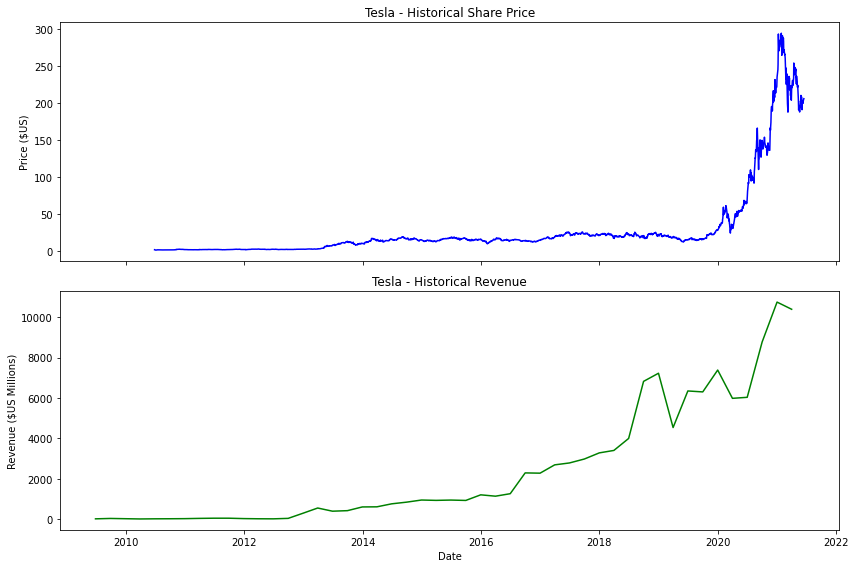

In [33]:
make_graph(tesla_data, tesla_revenue, 'Tesla')

## Question 6: Plot GameStop Stock Graph
Use the `make_graph` function to graph the GameStop Stock Data, also provide a title for the graph. The structure to call the `make_graph` function is `make_graph(gme_data, gme_revenue, 'GameStop')`. Note the graph will only show data upto June 2021.


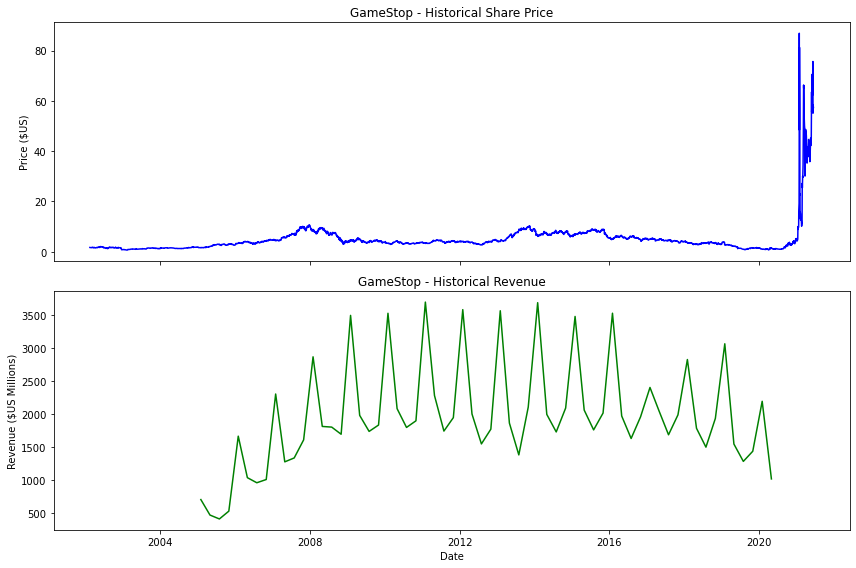

In [36]:
make_graph(gme_data, gme_revenue, 'GameStop')